In [10]:
from pathlib import Path

# Each eval dir is one timestamped output directory written by
# compute_metrics_junction_detection_nnunet_landmark_single_label.py containing metrics.csv and
# predictions_nnunet_landmark_single_label.csv. There's no per-class distinction to evaluate here
# (see that module's docstring) - localization only. The per-case probability-map .npz/.json outputs
# (from nnunet_landmark_predict_from_files(..., save_probabilities=True, single_channel=True)) are
# written alongside these into eval_dir.
EVAL_DIRS: list[Path] = [
    Path("/mnt/c/Users/juhe9/repos/MasterThesis/ForkSight/Data/nnunet_landmark_eval_output/Dataset013_nnUNetTrainerHeatmapAdaptiveWingFocalSoftSamplingSingleLabel/20260910_134813"),
    Path("/mnt/c/Users/juhe9/repos/MasterThesis/ForkSight/Data/nnunet_landmark_eval_output/Dataset014_nnUNetTrainerHeatmapAdaptiveWingFocalSoftSamplingSingleLabel/20260910_134925")
]

PLOT_PROBABILITY_MAPS = True

# Directory with the original (un-tiled) 4096x4096 PNG images, used as an underlay for the
# probability-map plots. File names here are NOT sanitized (may contain "_"/" "), unlike the
# .npz/.json case IDs written by the eval pipeline - a lookup is built at plot time by
# sanitizing each PNG's stem the same way (see _sanitize_case_id below), without renaming
# any files on disk.
ORIGINAL_IMAGES_DIR = Path(
    "/mnt/c/Users/juhe9/repos/MasterThesis/ForkSight/Data/RawData/junction_detection/images")

# relabeling_data.csv with the ground-truth junction annotations (x, y, label) for the
# evaluated test set - shared across all EVAL_DIRS runs, only used for the GT point overlay.
GT_ANNOTATIONS_CSV = Path(
    "/mnt/c/Users/juhe9/repos/MasterThesis/ForkSight/Data/RawData/junction_detection/relabeling_data.csv")

# Opacity of the underlying raw image, so the probability-map overlay on top of it stands
# out more clearly.
RAW_IMAGE_ALPHA = 0.3

# Opacity of the green probability-map overlay on top of the underlying image
# (per-pixel alpha is additionally scaled by each pixel's own (gamma-boosted) probability,
# so near-zero-probability regions stay transparent regardless of this value).
PROB_MAP_OVERLAY_ALPHA = 0.9

# Gamma correction (< 1) applied to each probability value before it's used for color/alpha,
# i.e. prob ** PROB_MAP_GAMMA. Values below 1 boost mid/low probabilities so weaker clusters
# and peaks stand out more clearly instead of fading into white; 1.0 = no boost (linear).
PROB_MAP_GAMMA = 0.5

# In addition to the actual (threshold=0.5) detected points, also run peak detection at
# these lower thresholds and print (not plot as points) any extra clusters only found there -
# i.e. landmarks that "almost" cleared the real detection threshold.
PROB_MAP_LOWER_THRESHOLDS = (0.4, 0.3)


In [11]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML


# repo root, so the pipeline's own GT-loading logic can be reused instead of duplicated here
sys.path.append(os.path.abspath(".."))
from Evaluation.compute_metrics_junction_detection import _load_gt_annotations

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)


In [12]:
def bold_best(df: pd.DataFrame, lower_is_better_cols: set[str] | None = None):
    """Return a Styler that bolds the best value in each column."""
    lower_is_better_cols = lower_is_better_cols or set()

    def _apply(s: pd.Series) -> list[str]:
        numeric = pd.to_numeric(s, errors="coerce")
        want_min = s.name in lower_is_better_cols
        best = numeric.min() if want_min else numeric.max()
        return [
            "font-weight: bold" if (not np.isnan(v) and v == best) else ""
            for v in numeric
        ]

    float_cols = df.select_dtypes(include="number").columns
    fmt = {c: "{:.4f}" for c in float_cols}
    return (
        df.style
        .apply(_apply, axis=0)
        .format(fmt, na_rep="–")
        .set_table_styles([{"selector": "th, td", "props": "font-family: inherit; font-size: inherit;"}])
    )


## Load Metrics

In [13]:
# Each metrics.csv is a single row (one run per compute_metrics_junction_detection_nnunet_landmark_single_label.py
# invocation, columns tp_loc/fp_loc/fn_loc/precision_loc/recall_loc/f1_loc only - see
# _compute_localization_metrics), so we stack one row per (label, eval_out_dir) pair into a single
# dataframe indexed by label.

def _get_dataset_trainer_from_eval_dir(eval_dir: Path) -> str:
    return eval_dir.parent.name

_rows = {}
for eval_dir in EVAL_DIRS:
    dataset_trainer = _get_dataset_trainer_from_eval_dir(eval_dir)
    csv_path = eval_dir / "metrics.csv"
    if not csv_path.is_file():
        raise FileNotFoundError(f"metrics.csv not found for '{dataset_trainer}' in {eval_dir}")
    df_one = pd.read_csv(csv_path)
    if len(df_one) != 1:
        raise ValueError(f"Expected a single-row metrics.csv for '{dataset_trainer}', got {len(df_one)} rows")
    _rows[dataset_trainer] = df_one.iloc[0]

df_jd = pd.DataFrame(_rows).T
df_jd.index.name = "Model"
print(f"Loaded junction localization metrics for {len(df_jd)} model(s):")

for eval_dir in EVAL_DIRS:
    dataset_trainer = _get_dataset_trainer_from_eval_dir(eval_dir)
    print(f"  {dataset_trainer}: {eval_dir}")


Loaded junction localization metrics for 2 model(s):
  Dataset013_nnUNetTrainerHeatmapAdaptiveWingFocalSoftSamplingSingleLabel: /mnt/c/Users/juhe9/repos/MasterThesis/ForkSight/Data/nnunet_landmark_eval_output/Dataset013_nnUNetTrainerHeatmapAdaptiveWingFocalSoftSamplingSingleLabel/20260910_134813
  Dataset014_nnUNetTrainerHeatmapAdaptiveWingFocalSoftSamplingSingleLabel: /mnt/c/Users/juhe9/repos/MasterThesis/ForkSight/Data/nnunet_landmark_eval_output/Dataset014_nnUNetTrainerHeatmapAdaptiveWingFocalSoftSamplingSingleLabel/20260910_134925


In [14]:
# Ground truth landmark counts (informative only - not asserted equal, since different runs being
# compared could in principle have evaluated different test sets). All non-Negative annotation types
# count as one combined "landmark" here, regardless of original 3-way/4-way type.
print("Ground truth landmarks in test set per model:")
for trainer in df_jd.index:
    tp = int(df_jd.loc[trainer, "tp_loc"])
    fn = int(df_jd.loc[trainer, "fn_loc"])
    print(f"  {trainer}: {tp + fn} landmark(s) (TP={tp}, FN={fn})")


Ground truth landmarks in test set per model:
  Dataset013_nnUNetTrainerHeatmapAdaptiveWingFocalSoftSamplingSingleLabel: 122 landmark(s) (TP=15, FN=107)
  Dataset014_nnUNetTrainerHeatmapAdaptiveWingFocalSoftSamplingSingleLabel: 122 landmark(s) (TP=18, FN=104)


### Localization Metrics

Class-agnostic: a prediction is a TP if it falls within the pixel matching threshold of *any* GT landmark, regardless of the landmark's original type - there's no per-class breakdown or type accuracy here, since the model was trained on a single combined label (see `JunctionDetection/PreProcessing/create_nnunet_dataset_variants.py` and `nnUNetTrainerHeatmapAdaptiveWingFocalSoftSamplingSingleLabel`).

Predictions come from `compute_metrics_junction_detection_nnunet_landmark_single_label.py`.

In [15]:
_LOC_DISPLAY_COLS = ["precision_loc", "recall_loc", "f1_loc", "tp_loc", "fp_loc", "fn_loc"]
_LOC_DISPLAY_RENAME = {
    "precision_loc": "Precision (loc)",
    "recall_loc":    "Recall (loc)",
    "f1_loc":        "F1 (loc)",
    "tp_loc":        "TP",
    "fp_loc":        "FP",
    "fn_loc":        "FN",
}

_cols_in_df = [c for c in _LOC_DISPLAY_COLS if c in df_jd.columns]
_sub = df_jd[_cols_in_df].copy()
_sub.columns = [_LOC_DISPLAY_RENAME.get(c, c) for c in _cols_in_df]
display(HTML("<h4>nnU-Net Landmark (Single-Label Heatmap Regression) - Localization Metrics</h4>"))
display(bold_best(_sub))


,Precision (loc),Recall (loc),F1 (loc),TP,FP,FN
Model,,,,,,
Dataset013_nnUNetTrainerHeatmapAdaptiveWingFocalSoftSamplingSingleLabel,0.7500,0.1230,0.2113,15.0000,5.0000,107.0000
Dataset014_nnUNetTrainerHeatmapAdaptiveWingFocalSoftSamplingSingleLabel,0.6667,0.1475,0.2416,18.0000,9.0000,104.0000


### Confusion Matrix

Rows = GT outcome (landmark / no GT). Columns = prediction outcome (found / not found). Cell % is row-normalised. Localization-only (no per-class breakdown) - see the explanation above.

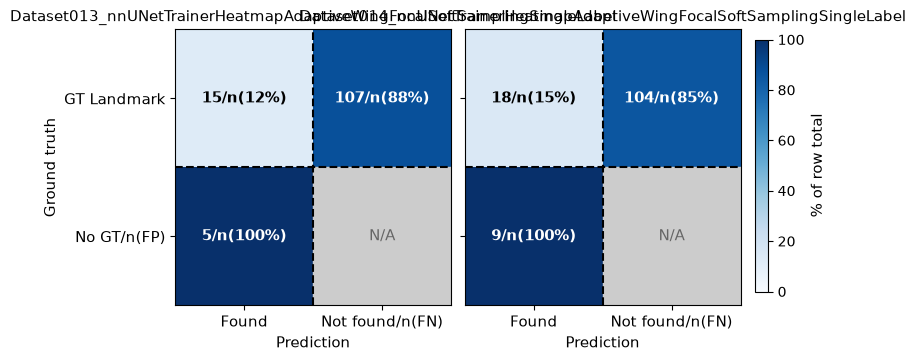

In [16]:
_CM_FONT = 11
_CM_COL_LABELS = ["Found", "Not found/n(FN)"]
_CM_ROW_LABELS = ["GT Landmark", "No GT/n(FP)"]


def _plot_cm_from_row(ax, row, title, show_x_labels=True, show_y_labels=True):
    cm = np.array([
        [row["tp_loc"], row["fn_loc"]],
        [row["fp_loc"], float("nan")],
    ], dtype=float)

    row_totals = np.array([
        row["tp_loc"] + row["fn_loc"],
        row["fp_loc"],
    ], dtype=float)

    with np.errstate(divide="ignore", invalid="ignore"):
        cm_pct = np.where(row_totals[:, None] > 0,
                          100.0 * cm / row_totals[:, None],
                          np.nan)

    masked = np.ma.masked_invalid(cm_pct)
    im = ax.imshow(masked, cmap="Blues", vmin=0, vmax=100, aspect="equal")

    ax.add_patch(plt.Rectangle((0.5, 0.5), 1, 1, color="#cccccc", zorder=2))
    ax.text(1, 1, "N/A", ha="center", va="center",
            fontsize=_CM_FONT, color="#666666", zorder=3)

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(_CM_COL_LABELS if show_x_labels else [""] * 2, fontsize=_CM_FONT)
    ax.set_yticklabels(_CM_ROW_LABELS if show_y_labels else [""] * 2, fontsize=_CM_FONT)
    if show_x_labels:
        ax.set_xlabel("Prediction", fontsize=_CM_FONT)
    if show_y_labels:
        ax.set_ylabel("Ground truth", fontsize=_CM_FONT)

    for r in range(2):
        for c in range(2):
            if r == 1 and c == 1:
                continue
            val = cm[r, c]
            if np.isnan(val):
                continue
            pct = cm_pct[r, c]
            pct_str = f"/n({pct:.0f}%)" if not np.isnan(pct) else ""
            text_color = "white" if (not np.isnan(pct) and pct > 60) else "black"
            ax.text(c, r, f"{int(val)}{pct_str}",
                    ha="center", va="center",
                    fontsize=_CM_FONT, color=text_color, fontweight="bold", zorder=4)

    ax.axhline(0.5, color="black", linewidth=1.5, linestyle="--")
    ax.axvline(0.5, color="black", linewidth=1.5, linestyle="--")
    ax.set_title(title, fontsize=_CM_FONT)
    return im


_cols = 2
_rows = (len(df_jd) + _cols - 1) // _cols
fig, axes = plt.subplots(_rows, _cols, figsize=(3.6 * _cols, 3.6 * _rows), squeeze=False)

im = None
for i, dataset_trainer in enumerate(df_jd.index):
    r, c = i // _cols, i % _cols
    ax = axes[r][c]
    im = _plot_cm_from_row(
        ax, df_jd.loc[dataset_trainer], str(dataset_trainer),
        show_x_labels=(r == _rows - 1),
        show_y_labels=(c == 0),
    )

for ax in axes.flat[len(df_jd):]:
    ax.set_visible(False)

plt.subplots_adjust(wspace=0.05, hspace=0.15, right=0.91)

cbar_ax = fig.add_axes([0.93, 0.15, 0.018, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("% of row total", fontsize=_CM_FONT)
cbar.ax.tick_params(labelsize=_CM_FONT - 1)

plt.show()
plt.close()


## Predicted Probability Maps

Renders each per-case heatmap-regression probability map (from the `.npz` files saved by `nnunet_landmark_predict_from_files(..., save_probabilities=True, single_channel=True)`) as a single image per case: the original 4096x4096 raw image (dimmed to `RAW_IMAGE_ALPHA`), with the single combined-landmark probability overlaid white&rarr;green - semi-transparent (fully transparent where probability is ~0) and gamma-boosted (`PROB_MAP_GAMMA`) so clusters and peaks stand out more clearly. Predicted and ground-truth junction points are plotted as open circles on top (magenta = prediction; lime/orange = GT 3-way/4-way, shown for context even though the single-label model doesn't predict type; small solid circles = prediction, larger dashed circles = GT, so neither obstructs the probability blobs much), with a legend. Runs once per entry in `EVAL_DIRS`; plots are saved to `eval_dir / "plot"`.

For every case, also detects (but does not plot) landmark clusters that would only appear at the lower thresholds in `PROB_MAP_LOWER_THRESHOLDS` (e.g. 0.4, 0.3) - these are printed as text, to surface near-miss detections that didn't clear the real (0.5) threshold.

Only runs if `PLOT_PROBABILITY_MAPS` is set to `True` in the config cell above.

In [17]:
import gc
import time

try:
    import psutil
    _HAS_PSUTIL = True
except ImportError:
    _HAS_PSUTIL = False
    print("psutil not installed - the memory-headroom safeguard below will be a no-op "
          "(only the fixed inter-plot sleep still applies). `pip install psutil` to enable it.")

if PLOT_PROBABILITY_MAPS:
    import matplotlib.patches as mpatches
    from PIL import Image
    from skimage.feature import peak_local_max

    # --- crash-safeguard knobs --------------------------------------------------------
    # Each probability map is 4096x4096; the colored overlay built below is a full-resolution
    # float32 RGBA array (~256MB) that matplotlib then holds a reference to for the lifetime of
    # the Figure. Figures/Axes/Artists form internal reference cycles (canvas, callback
    # registries, etc.) that plain refcounting does NOT release - only a real gc.collect() does.
    # Without forcing that every iteration, a burst of unreclaimed figures/arrays can exceed a
    # small WSL2 VM's fixed memory budget and crash the whole VM instead of just this kernel.
    # These knobs trade a bit of speed for headroom; tune PLOT_SLEEP_SECONDS /
    # PLOT_MIN_AVAILABLE_GB down if this turns out to be overly conservative.
    PLOT_SLEEP_SECONDS = 0.3              # heuristic pause after every plot - throttles alloc/I/O bursts
    PLOT_GC_EVERY_N = 1                   # force a full gc.collect() every N images (1 = every image)
    PLOT_MIN_AVAILABLE_GB = 1.0           # abort rather than risk a crash below this much free RAM
    PLOT_LOW_MEM_RETRIES = 5
    PLOT_LOW_MEM_RETRY_SLEEP_SECONDS = 3.0

    def _available_gb() -> float | None:
        if not _HAS_PSUTIL:
            return None
        return psutil.virtual_memory().available / (1024 ** 3)

    def _wait_for_memory_headroom(context: str) -> bool:
        """Blocks (with retries + forced gc) until free memory clears PLOT_MIN_AVAILABLE_GB.
        Returns False (caller should abort) if it's still critically low afterwards. No-op
        (always True) if psutil isn't available to check with."""
        avail = _available_gb()
        if avail is None or avail >= PLOT_MIN_AVAILABLE_GB:
            return True
        for attempt in range(1, PLOT_LOW_MEM_RETRIES + 1):
            print(f"  [memory guard] only {avail:.2f} GB free before {context} "
                  f"(need {PLOT_MIN_AVAILABLE_GB:.1f} GB) - forcing gc + pausing "
                  f"(attempt {attempt}/{PLOT_LOW_MEM_RETRIES})...")
            plt.close("all")
            gc.collect()
            time.sleep(PLOT_LOW_MEM_RETRY_SLEEP_SECONDS)
            avail = _available_gb()
            if avail >= PLOT_MIN_AVAILABLE_GB:
                return True
        print(f"  [memory guard] still only {avail:.2f} GB free after {PLOT_LOW_MEM_RETRIES} "
              f"retries - aborting remaining plots to avoid a WSL crash. Free up host RAM "
              f"(or restart the kernel) and re-run this cell; already-saved plots are skipped "
              f"on the next pass.")
        return False

    _MIN_DISTANCE = 3      # matches NNUNET_LANDMARK_DEFAULT_MIN_DISTANCE
    _DEFAULT_THRESHOLD = 0.5  # matches NNUNET_LANDMARK_DEFAULT_THRESHOLD
    _PRED_MARKER_RADIUS = 45
    _GT_MARKER_RADIUS = 55

    # export_single_channel_heatmap_prediction_from_logits writes exactly one heatmap channel
    # (the dataset's sole foreground label - see create_nnunet_dataset_variants.py); channel 0
    # is that landmark's probability map (not a "combined" channel to skip, unlike the
    # multi-class export).
    _PROB_MAP_CHANNEL = (0, "Landmark", (0.0, 0.6, 0.0))  # green

    # Predictions: small solid-outline circles (single class - "Landmark", the placeholder
    # pred_type written by compute_metrics_junction_detection_nnunet_landmark_single_label.py).
    # GT: larger dashed-outline circles, still split by the annotation's real 3-way/4-way type
    # (informative context only - the model itself doesn't predict type) so GT markers don't
    # obstruct the probability blobs the way filled/crossed markers would.
    _MARKER_STYLE = {
        ("pred", "Landmark"): dict(color="magenta", linestyle="-", radius=_PRED_MARKER_RADIUS, label="Pred landmark", linewidth=0.5),
        ("gt", "3-way"): dict(color="lime", linestyle="--", radius=_GT_MARKER_RADIUS, label="GT 3-way", linewidth=0.5),
        ("gt", "4-way"): dict(color="orange", linestyle="--", radius=_GT_MARKER_RADIUS, label="GT 4-way", linewidth=0.5),
    }

    def _sanitize_case_id(img_name: str) -> str:
        # mirrors compute_metrics_junction_detection_nnunet_landmark._sanitize_case_id
        return img_name.replace("_", "-").replace(" ", "-")

    def _build_sanitized_png_lookup(image_dir: Path) -> dict[str, Path]:
        """Maps sanitized-case-id -> original PNG path, without renaming anything on disk."""
        lookup: dict[str, Path] = {}
        for p in sorted(Path(image_dir).glob("*.png")):
            key = _sanitize_case_id(p.stem)
            if key in lookup:
                raise ValueError(
                    f"Sanitized PNG name collision: '{p.name}' and '{lookup[key].name}' "
                    f"both sanitize to '{key}' - cannot disambiguate which is case '{key}'.")
            lookup[key] = p
        return lookup

    def _colored_prob_overlay(prob_map: np.ndarray, color_rgb: tuple, alpha_scale: float,
                              gamma: float = 1.0) -> np.ndarray:
        """White-to-`color_rgb` gradient in RGB, with per-pixel alpha = prob**gamma * alpha_scale,
        so near-zero-probability pixels stay transparent instead of hazing over the whole image,
        and (for gamma < 1) mid/low probabilities are boosted so weaker clusters stand out more."""
        color = np.asarray(color_rgb, dtype=np.float32)
        prob = np.clip(prob_map, 0.0, 1.0).astype(np.float32) ** gamma
        rgb = 1.0 - prob[..., None] * (1.0 - color)
        alpha = prob * alpha_scale
        return np.dstack([rgb, alpha])

    def _peak_coords(channel_map: np.ndarray, threshold: float) -> dict[tuple[int, int], float]:
        coords = peak_local_max(
            channel_map, min_distance=_MIN_DISTANCE, threshold_abs=threshold)
        return {(int(x), int(y)): float(channel_map[y, x]) for y, x in coords}

    png_lookup = _build_sanitized_png_lookup(ORIGINAL_IMAGES_DIR)
    print(f"Found {len(png_lookup)} original image(s) in {ORIGINAL_IMAGES_DIR}")

    gt_by_image = _load_gt_annotations(GT_ANNOTATIONS_CSV)
    print(
        f"Loaded GT annotations for {len(gt_by_image)} image(s) from {GT_ANNOTATIONS_CSV}")

    _aborted = False

    for eval_dir in EVAL_DIRS:
        if _aborted:
            break

        dataset_trainer = _get_dataset_trainer_from_eval_dir(eval_dir)
        prob_map_plot_out_dir = eval_dir / "plot"

        _npz_paths = sorted(eval_dir.glob("*.npz"))
        if not _npz_paths:
            print(f"[{dataset_trainer}] No .npz probability maps found in {eval_dir}")
            continue

        pred_csv_path = eval_dir / "predictions_nnunet_landmark_single_label.csv"
        if not pred_csv_path.is_file():
            raise FileNotFoundError(
                f"predictions_nnunet_landmark_single_label.csv not found for '{dataset_trainer}' in {eval_dir}")
        pred_df = pd.read_csv(pred_csv_path)

        prob_map_plot_out_dir.mkdir(parents=True, exist_ok=True)

        n_plotted = 0
        near_miss_report: list[tuple[str, str, float, dict]] = []

        for idx, npz_path in enumerate(_npz_paths):
            case_id = npz_path.stem
            out_path = prob_map_plot_out_dir / f"{case_id}.png"

            if out_path.exists():
                # print(f"plot {out_path.name} already exists, skipping")
                continue

            if not _wait_for_memory_headroom(f"case '{case_id}'"):
                _aborted = True
                break

            fig = None
            raw_img = None
            probabilities = None
            try:
                probabilities = np.load(
                    npz_path)["probabilities"].astype(np.float32)
                # revert_heatmap_to_original_geometry keeps a singleton z-axis for 2D configs
                # (shape (C, 1, H, W)); drop it so the channel is a plain (H, W) image.
                if probabilities.ndim == 4 and probabilities.shape[1] == 1:
                    probabilities = probabilities[:, 0]

                channel, channel_label, color = _PROB_MAP_CHANNEL
                channel_map = probabilities[channel]

                # --- near-miss cluster detection at lower thresholds (text only, no plotting) ---
                prev_coords = set(_peak_coords(channel_map, _DEFAULT_THRESHOLD))
                for lower_thresh in PROB_MAP_LOWER_THRESHOLDS:
                    peaks_lower = _peak_coords(channel_map, lower_thresh)
                    new_coords = {xy: score for xy, score in peaks_lower.items()
                                  if xy not in prev_coords}
                    if new_coords:
                        near_miss_report.append(
                            (case_id, channel_label, lower_thresh, new_coords))
                    prev_coords |= set(peaks_lower)

                # --- probability-map + points plot ---
                png_path = png_lookup.get(case_id)
                if png_path is None:
                    print(f"[{dataset_trainer}] {case_id}: no matching PNG found in "
                          f"{ORIGINAL_IMAGES_DIR}, skipping plot")
                    continue
                # the un-sanitized stem, as used in predictions_nnunet_landmark_single_label.csv's
                # "image" column and relabeling_data.csv's "image" column
                stem = png_path.stem

                # `with` closes the PIL file handle (and its internal decode buffers)
                # as soon as the array copy is made, instead of leaving it open for GC.
                with Image.open(png_path) as _img:
                    raw_img = np.array(_img)
                orig_h, orig_w = raw_img.shape[:2]
                extent = [0, orig_w, orig_h, 0]

                fig, ax = plt.subplots(figsize=(10, 10))
                ax.imshow(raw_img, cmap="gray" if raw_img.ndim == 2 else None,
                          extent=extent, alpha=RAW_IMAGE_ALPHA)
                overlay = _colored_prob_overlay(
                    channel_map, color, PROB_MAP_OVERLAY_ALPHA, gamma=PROB_MAP_GAMMA)
                ax.imshow(overlay, extent=extent)
                del overlay  # matplotlib now holds the reference it needs; drop ours

                plotted_labels: set[str] = set()

                def _scatter(points, kind):
                    for x, y, jtype in points:
                        style = _MARKER_STYLE[(kind, jtype)]
                        label = style["label"] if style["label"] not in plotted_labels else None
                        plotted_labels.add(style["label"])
                        circle = mpatches.Circle(
                            (x, y), radius=style["radius"], fill=False,
                            edgecolor=style["color"], linestyle=style["linestyle"],
                            linewidth=2.0, alpha=0.95, label=label, zorder=5)
                        ax.add_patch(circle)

                pred_rows = pred_df[pred_df["image"] == stem]
                _scatter([(r.x, r.y, r.pred_type)
                         for r in pred_rows.itertuples()], "pred")
                _scatter([(a["x"], a["y"], a["type"])
                         for a in gt_by_image.get(stem, [])], "gt")

                ax.set_xlim(0, orig_w)
                ax.set_ylim(orig_h, 0)
                ax.set_aspect("equal")
                ax.axis("off")

                handles, labels = ax.get_legend_handles_labels()
                handles += [mpatches.Patch(color=color, alpha=0.5,
                                           label=f"{channel_label} prob.")]
                labels += [f"{channel_label} prob."]
                ax.legend(handles, labels, loc="upper right",
                          fontsize=8, framealpha=0.85)

                ax.set_title(f"{dataset_trainer} - {case_id}", fontsize=11)
                plt.tight_layout()
                fig.savefig(out_path, dpi=150, bbox_inches="tight")
                n_plotted += 1
            finally:
                # Always close/free, even if an exception was raised above - a figure or a
                # large array leaked on error is exactly the kind of thing that compounds
                # into an OOM crash over a long EVAL_DIRS run.
                if fig is not None:
                    fig.clf()
                    plt.close(fig)
                del raw_img, probabilities, fig
                if idx % PLOT_GC_EVERY_N == 0:
                    gc.collect()

            # heuristic throttle: give the OS a moment to actually reclaim the freed
            # memory (and settle any pending I/O to the eval_dir, often on /mnt/c) before
            # the next iteration's allocation burst starts.
            time.sleep(PLOT_SLEEP_SECONDS)

        plt.close("all")
        gc.collect()

        print(
            f"[{dataset_trainer}] Saved {n_plotted} probability map plot(s) to {prob_map_plot_out_dir}")

        if near_miss_report:
            print(f"[{dataset_trainer}] Near-miss clusters (below threshold={_DEFAULT_THRESHOLD}, "
                  f"min_distance={_MIN_DISTANCE}):")
            for case_id, channel_label, thr, coords in near_miss_report:
                pts = ", ".join(
                    f"(x={x}, y={y}, score={s:.3f})" for (x, y), s in coords.items())
                print(
                    f"    {case_id} | {channel_label} | threshold={thr}: {pts}")
        else:
            print(f"[{dataset_trainer}] No near-miss clusters found at thresholds "
                  f"{PROB_MAP_LOWER_THRESHOLDS}.")

    if _aborted:
        print("/nAborted early due to low memory - free up RAM (or restart the kernel) and "
              "re-run this cell to resume; already-saved plots will be skipped.")
else:
    print("PLOT_PROBABILITY_MAPS is False - skipping probability map plots.")


Found 100 original image(s) in /mnt/c/Users/juhe9/repos/MasterThesis/ForkSight/Data/RawData/junction_detection/images
Loaded GT annotations for 100 image(s) from /mnt/c/Users/juhe9/repos/MasterThesis/ForkSight/Data/RawData/junction_detection/relabeling_data.csv
[Dataset013_nnUNetTrainerHeatmapAdaptiveWingFocalSoftSamplingSingleLabel] Saved 100 probability map plot(s) to /mnt/c/Users/juhe9/repos/MasterThesis/ForkSight/Data/nnunet_landmark_eval_output/Dataset013_nnUNetTrainerHeatmapAdaptiveWingFocalSoftSamplingSingleLabel/20260910_134813/plot
[Dataset013_nnUNetTrainerHeatmapAdaptiveWingFocalSoftSamplingSingleLabel] Near-miss clusters (below threshold=0.5, min_distance=3):
    20250409-veronica-apple-tileset-14-tile-014-006 | Landmark | threshold=0.4: (x=737, y=465, score=0.410)
    Dani-Funghi-TileSet-6-Tile-015-001 | Landmark | threshold=0.3: (x=104, y=70, score=0.385)
    Dani-Funghi-TileSet-9-Tile-002-008 | Landmark | threshold=0.3: (x=16, y=649, score=0.324)
    Dani-Margherita-TileS